In [1]:
import pandas as pd
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [4]:

df = pd.read_excel("Copy of default of credit card clients-Copy1.xls" ,header = 1)
print (df.head())

   ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0   1      20000    2          2         1   24      2      2     -1     -1   
1   2     120000    2          2         2   26     -1      2      0      0   
2   3      90000    2          2         2   34      0      0      0      0   
3   4      50000    2          2         1   37      0      0      0      0   
4   5      50000    1          2         1   57     -1      0     -1      0   

   ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0  ...          0          0          0         0       689         0   
1  ...       3272       3455       3261         0      1000      1000   
2  ...      14331      14948      15549      1518      1500      1000   
3  ...      28314      28959      29547      2000      2019      1200   
4  ...      20940      19146      19131      2000     36681     10000   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  default payment next month  
0         0         0   

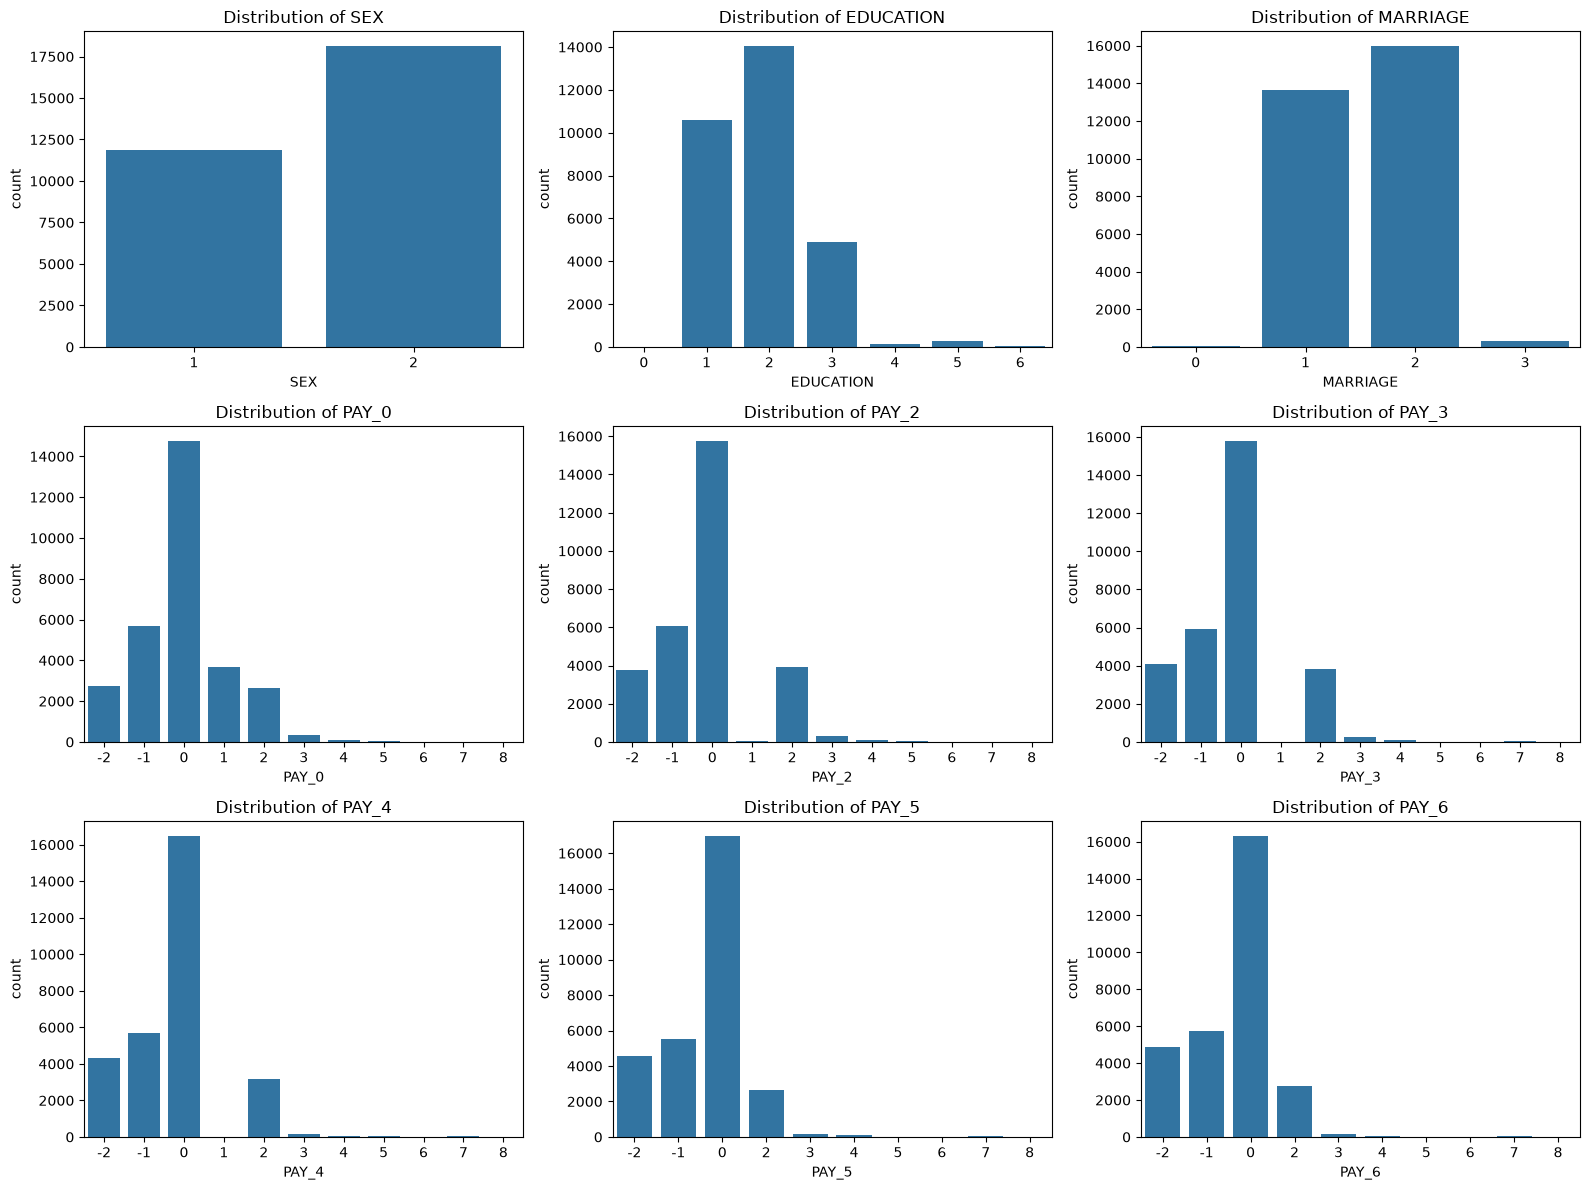

In [5]:
categorical_cols = [
    'SEX', 'EDUCATION', 'MARRIAGE',
    'PAY_0', 'PAY_2', 'PAY_3',
    'PAY_4', 'PAY_5', 'PAY_6'
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for col, ax in zip(categorical_cols, axes.flatten()):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

In [12]:
#average credit limit#
df.groupby('default payment next month')['LIMIT_BAL'].mean()

default payment next month
0    178099.726074
1    130109.656420
Name: LIMIT_BAL, dtype: float64

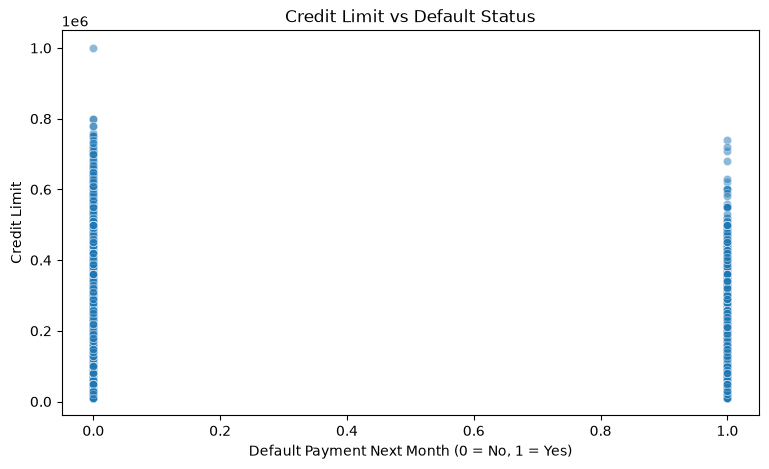

In [11]:
'''
answers the question "does credit limit/utilization affects likelihood of defaulting"
'''
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='default payment next month',
    y='LIMIT_BAL',
    alpha=0.5
)

plt.title('Credit Limit vs Default Status')
plt.xlabel('Default Payment Next Month (0 = No, 1 = Yes)')
plt.ylabel('Credit Limit')
plt.show()

In [13]:
#Average repayment Status#
pay_cols = [
    'PAY_6', 'PAY_5', 'PAY_4',
    'PAY_3', 'PAY_2', 'PAY_0'
]

repayment_pattern = df.groupby("default payment next month")[pay_cols].mean()

repayment_pattern

,PAY_6,PAY_5,PAY_4,PAY_3,PAY_2,PAY_0
default payment next month,,,,,,
0,-0.405624,-0.389488,-0.355633,-0.316256,-0.301917,-0.211222
1,0.112116,0.167872,0.254521,0.362116,0.458258,0.668174


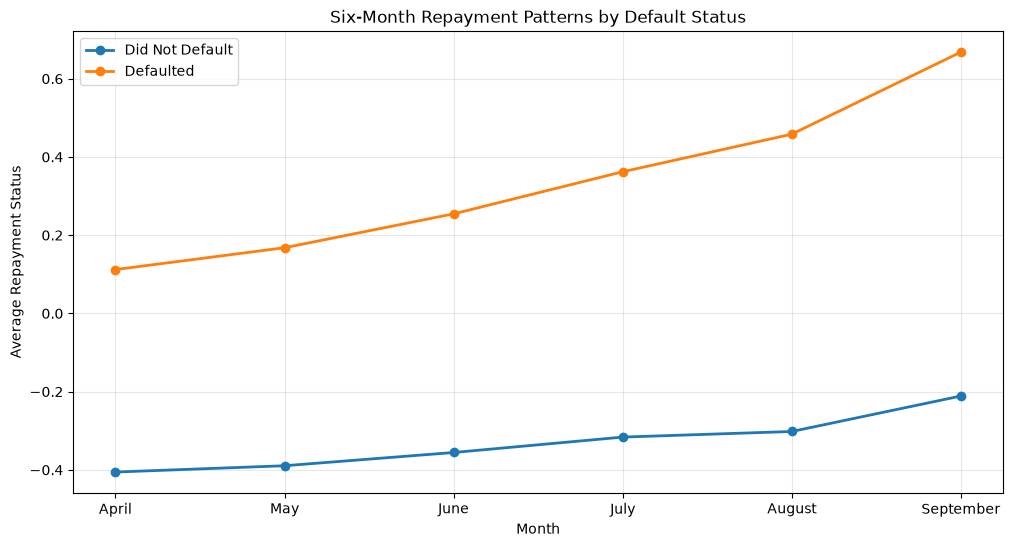

In [10]:
#
plt.figure(figsize=(12, 6))

months = ['April', 'May', 'June', 'July', 'August', 'September']

for default_status in [0, 1]:

    plt.plot(
        months,
        repayment_pattern.loc[default_status],
        marker='o',
        linewidth=2,
        label='Defaulted' if default_status == 1 else 'Did Not Default'
    )

plt.title('Six-Month Repayment Patterns by Default Status')
plt.xlabel('Month')
plt.ylabel('Average Repayment Status')

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()